In [111]:
import pandas as pd
data = pd.read_csv("rainfall in india 1901-2015.csv")
print(data.head)

<bound method NDFrame.head of                     SUBDIVISION  YEAR   JAN    FEB   MAR    APR    MAY    JUN  \
0     ANDAMAN & NICOBAR ISLANDS  1901  49.2   87.1  29.2    2.3  528.8  517.5   
1     ANDAMAN & NICOBAR ISLANDS  1902   0.0  159.8  12.2    0.0  446.1  537.1   
2     ANDAMAN & NICOBAR ISLANDS  1903  12.7  144.0   0.0    1.0  235.1  479.9   
3     ANDAMAN & NICOBAR ISLANDS  1904   9.4   14.7   0.0  202.4  304.5  495.1   
4     ANDAMAN & NICOBAR ISLANDS  1905   1.3    0.0   3.3   26.9  279.5  628.7   
...                         ...   ...   ...    ...   ...    ...    ...    ...   
4111                LAKSHADWEEP  2011   5.1    2.8   3.1   85.9  107.2  153.6   
4112                LAKSHADWEEP  2012  19.2    0.1   1.6   76.8   21.2  327.0   
4113                LAKSHADWEEP  2013  26.2   34.4  37.5    5.3   88.3  426.2   
4114                LAKSHADWEEP  2014  53.2   16.1   4.4   14.9   57.4  244.1   
4115                LAKSHADWEEP  2015   2.2    0.5   3.7   87.1  133.1  296.6  

In [112]:
!pip install pandas numpy matplotlib seaborn scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [113]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [114]:
df = pd.read_csv(
    "rainfall in india 1901-2015 (1).csv"
)

print(df.head())

                 SUBDIVISION  YEAR   JAN    FEB   MAR    APR    MAY    JUN  \
0  ANDAMAN & NICOBAR ISLANDS  1901  49.2   87.1  29.2    2.3  528.8  517.5   
1  ANDAMAN & NICOBAR ISLANDS  1902   0.0  159.8  12.2    0.0  446.1  537.1   
2  ANDAMAN & NICOBAR ISLANDS  1903  12.7  144.0   0.0    1.0  235.1  479.9   
3  ANDAMAN & NICOBAR ISLANDS  1904   9.4   14.7   0.0  202.4  304.5  495.1   
4  ANDAMAN & NICOBAR ISLANDS  1905   1.3    0.0   3.3   26.9  279.5  628.7   

     JUL    AUG    SEP    OCT    NOV    DEC  ANNUAL  Jan-Feb  Mar-May  \
0  365.1  481.1  332.6  388.5  558.2   33.6  3373.2    136.3    560.3   
1  228.9  753.7  666.2  197.2  359.0  160.5  3520.7    159.8    458.3   
2  728.4  326.7  339.0  181.2  284.4  225.0  2957.4    156.7    236.1   
3  502.0  160.1  820.4  222.2  308.7   40.1  3079.6     24.1    506.9   
4  368.7  330.5  297.0  260.7   25.4  344.7  2566.7      1.3    309.7   

   Jun-Sep  Oct-Dec  
0   1696.3    980.3  
1   2185.9    716.7  
2   1874.0    690.6  
3   

In [115]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (4116, 19)

Column Names:
Index(['SUBDIVISION', 'YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL',
       'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'ANNUAL', 'Jan-Feb', 'Mar-May',
       'Jun-Sep', 'Oct-Dec'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 4116 entries, 0 to 4115
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SUBDIVISION  4116 non-null   str    
 1   YEAR         4116 non-null   int64  
 2   JAN          4112 non-null   float64
 3   FEB          4113 non-null   float64
 4   MAR          4110 non-null   float64
 5   APR          4112 non-null   float64
 6   MAY          4113 non-null   float64
 7   JUN          4111 non-null   float64
 8   JUL          4109 non-null   float64
 9   AUG          4112 non-null   float64
 10  SEP          4110 non-null   float64
 11  OCT          4109 non-null   float64
 12  NOV          4105 non-null   float64
 13  DEC 

In [116]:
print(df.isnull().sum())

SUBDIVISION     0
YEAR            0
JAN             4
FEB             3
MAR             6
APR             4
MAY             3
JUN             5
JUL             7
AUG             4
SEP             6
OCT             7
NOV            11
DEC            10
ANNUAL         26
Jan-Feb         6
Mar-May         9
Jun-Sep        10
Oct-Dec        13
dtype: int64


In [117]:
df = df.dropna(subset=["ANNUAL"])

print("Shape after cleaning:", df.shape)

Shape after cleaning: (4090, 19)


In [118]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 0
Shape after removing duplicates: (4090, 19)


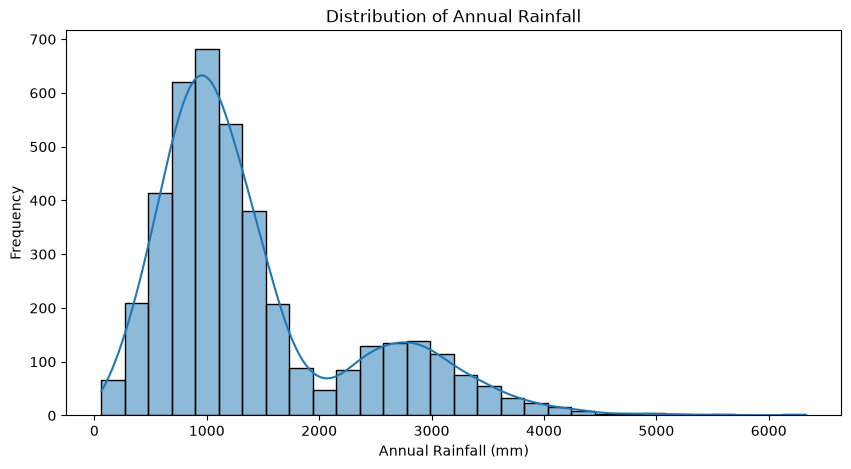

In [119]:
plt.figure(figsize=(10,5))

sns.histplot(
    df["ANNUAL"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Annual Rainfall")
plt.xlabel("Annual Rainfall (mm)")
plt.ylabel("Frequency")

plt.show()

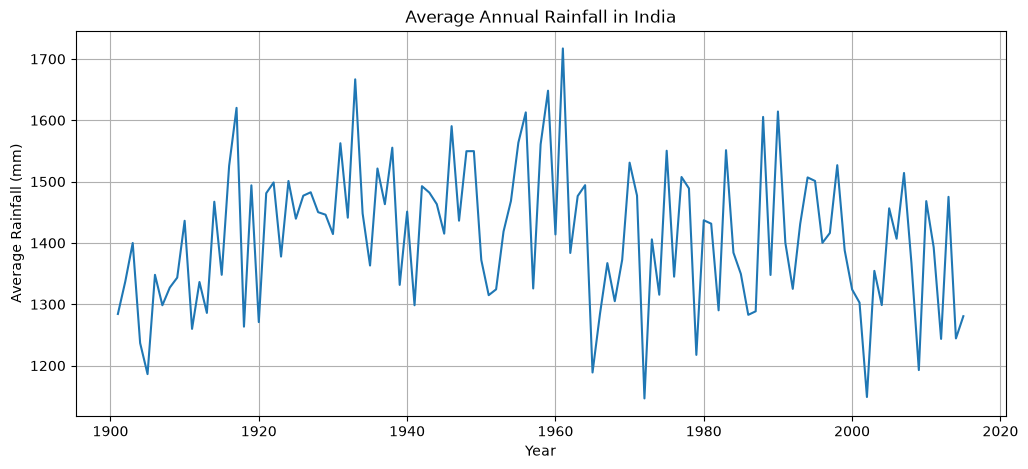

In [120]:
yearly = df.groupby("YEAR")["ANNUAL"].mean()

plt.figure(figsize=(12,5))

plt.plot(yearly.index, yearly.values)

plt.title("Average Annual Rainfall in India")
plt.xlabel("Year")
plt.ylabel("Average Rainfall (mm)")

plt.grid()
plt.show()

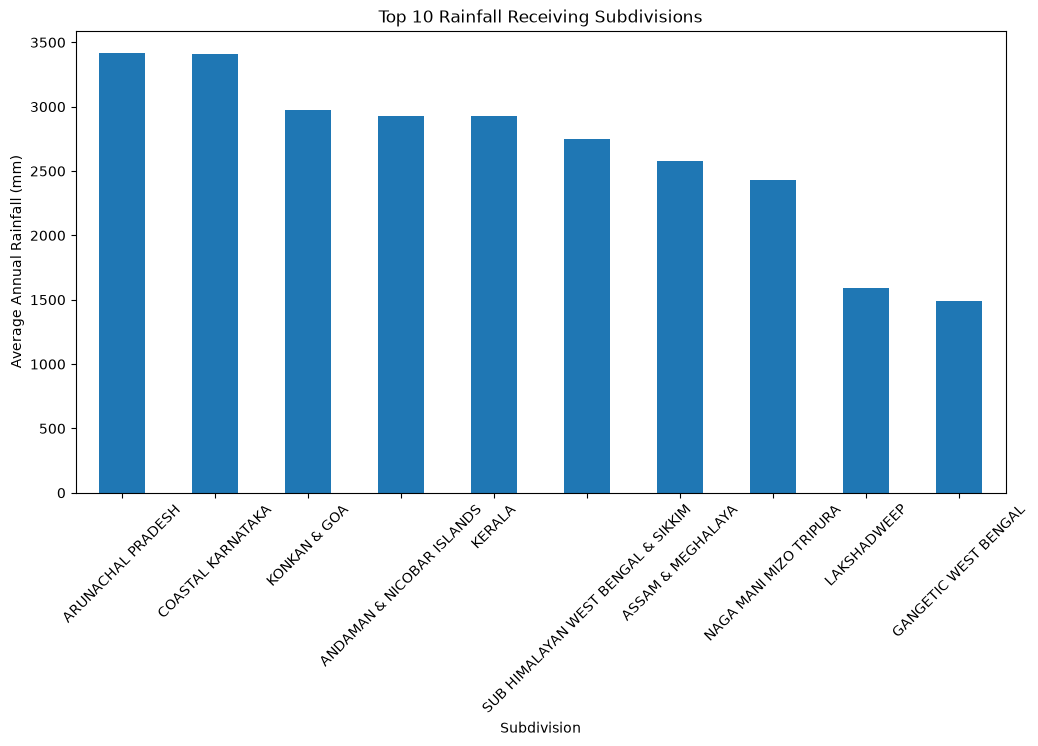

In [121]:
top_regions = (
    df.groupby("SUBDIVISION")["ANNUAL"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))

top_regions.plot(kind="bar")

plt.title("Top 10 Rainfall Receiving Subdivisions")
plt.xlabel("Subdivision")
plt.ylabel("Average Annual Rainfall (mm)")

plt.xticks(rotation=45)
plt.show()

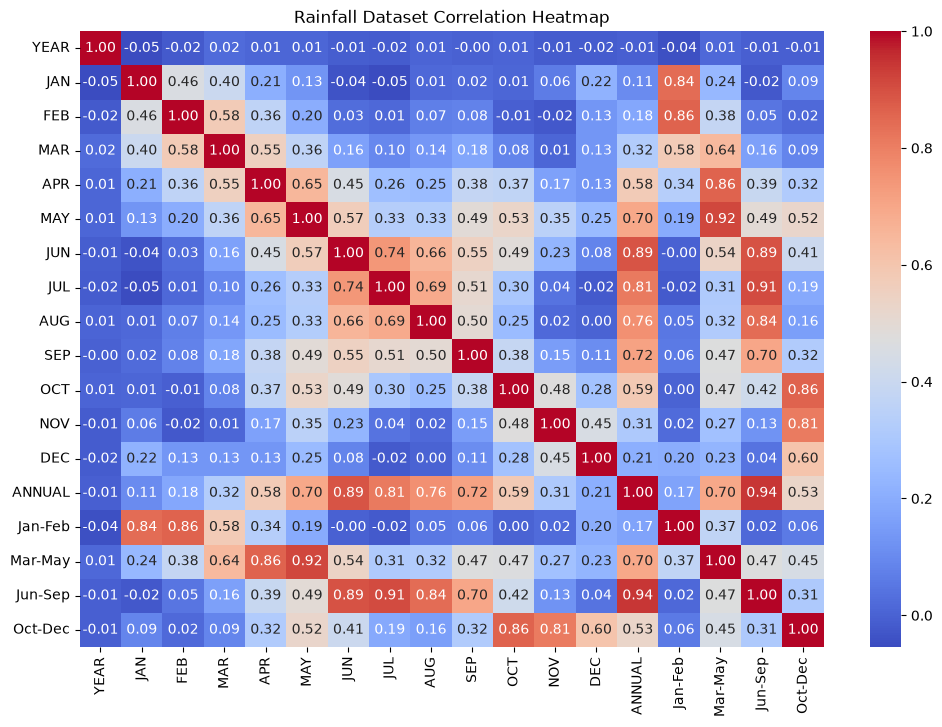

In [122]:
plt.figure(figsize=(12,8))

corr = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Rainfall Dataset Correlation Heatmap")
plt.show()

In [123]:
df = df.sort_values(
    ["SUBDIVISION", "YEAR"]
).copy()

df["PREVIOUS_ANNUAL"] = (
    df.groupby("SUBDIVISION")["ANNUAL"]
    .shift(1)
)

df["PREVIOUS_MONSOON"] = (
    df.groupby("SUBDIVISION")["Jun-Sep"]
    .shift(1)
)

df = df.dropna(
    subset=["ANNUAL", "PREVIOUS_ANNUAL",
            "PREVIOUS_MONSOON"]
)

print(df.head())

                 SUBDIVISION  YEAR   JAN    FEB   MAR    APR    MAY    JUN  \
1  ANDAMAN & NICOBAR ISLANDS  1902   0.0  159.8  12.2    0.0  446.1  537.1   
2  ANDAMAN & NICOBAR ISLANDS  1903  12.7  144.0   0.0    1.0  235.1  479.9   
3  ANDAMAN & NICOBAR ISLANDS  1904   9.4   14.7   0.0  202.4  304.5  495.1   
4  ANDAMAN & NICOBAR ISLANDS  1905   1.3    0.0   3.3   26.9  279.5  628.7   
5  ANDAMAN & NICOBAR ISLANDS  1906  36.6    0.0   0.0    0.0  556.1  733.3   

     JUL    AUG  ...    OCT    NOV    DEC  ANNUAL  Jan-Feb  Mar-May  Jun-Sep  \
1  228.9  753.7  ...  197.2  359.0  160.5  3520.7    159.8    458.3   2185.9   
2  728.4  326.7  ...  181.2  284.4  225.0  2957.4    156.7    236.1   1874.0   
3  502.0  160.1  ...  222.2  308.7   40.1  3079.6     24.1    506.9   1977.6   
4  368.7  330.5  ...  260.7   25.4  344.7  2566.7      1.3    309.7   1624.9   
5  247.7  320.5  ...  267.8  128.9   79.2  2534.4     36.6    556.1   1465.8   

   Oct-Dec  PREVIOUS_ANNUAL  PREVIOUS_MONSOON  
1 

In [124]:
X = df[
    [
        "YEAR",
        "SUBDIVISION",
        "PREVIOUS_ANNUAL",
        "PREVIOUS_MONSOON"
    ]
]

y = df["ANNUAL"]

print("Input Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input Features:
   YEAR                SUBDIVISION  PREVIOUS_ANNUAL  PREVIOUS_MONSOON
1  1902  ANDAMAN & NICOBAR ISLANDS           3373.2            1696.3
2  1903  ANDAMAN & NICOBAR ISLANDS           3520.7            2185.9
3  1904  ANDAMAN & NICOBAR ISLANDS           2957.4            1874.0
4  1905  ANDAMAN & NICOBAR ISLANDS           3079.6            1977.6
5  1906  ANDAMAN & NICOBAR ISLANDS           2566.7            1624.9

Target:
1    3520.7
2    2957.4
3    3079.6
4    2566.7
5    2534.4
Name: ANNUAL, dtype: float64


In [125]:
train = df[df["YEAR"] <= 2000]

test = df[df["YEAR"] > 2000]

X_train = train[
    ["YEAR", "SUBDIVISION",
     "PREVIOUS_ANNUAL", "PREVIOUS_MONSOON"]
]

y_train = train["ANNUAL"]

X_test = test[
    ["YEAR", "SUBDIVISION",
     "PREVIOUS_ANNUAL", "PREVIOUS_MONSOON"]
]

y_test = test["ANNUAL"]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 3516
Testing records: 538


In [126]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

numeric_features = [
    "YEAR",
    "PREVIOUS_ANNUAL",
    "PREVIOUS_MONSOON"
]

categorical_features = ["SUBDIVISION"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [127]:
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression Training Completed!")

Linear Regression Training Completed!


In [128]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [129]:
def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    r2 = r2_score(actual, predicted)

    print("\n", name)

    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))

    return mae, rmse, r2